# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Gita Antonia Sipayung
- **Email:** gitasipayung04@gmail.com
- **ID Dicoding:** ds297b6x0678

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah kerangka untuk merumuskan pertanyaan secara terstruktur agar analisis menghasilkan informasi yang relevan.

* **Specific (Spesifik)**
  * Pertanyaan jelas, fokus pada topik tertentu, dan tidak bermakna ganda.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa yang memengaruhi penurunan penjualan produk elektronik di Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan dapat dijawab dengan angka atau matriks yang konkret.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata kepuasan pelanggan bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Jawaban memberi arahan untuk tindakan nyata.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa yang paling sering digunakan sebelum pengguna melakukan checkout?
* **Relevant (Relevan)**
  * Pertanyaan sejalan dengan tujuan bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan stok gudang saat masalah utamanya efektivitas kampanye media sosial.
    * Benar: Apakah iklan Instagram memberikan ROAS lebih tinggi daripada iklan TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan memiliki batas waktu yang jelas.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa pertumbuhan pengguna baru secara bulanan sepanjang 2025?


**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Musim dan kondisi cuaca apa yang menghasilkan rata-rata penyewaan sepeda harian tertinggi dan terendah sepanjang 2011–2012, dan berapa persen selisihnya, agar operator dapat mengatur jumlah armada dan jadwal perawatan sepeda per musim?
- **Pertanyaan 2:** Bagaimana perbandingan rata-rata penyewaan harian pengguna casual dan registered pada hari kerja dibanding hari libur/akhir pekan selama 2011–2012, dan berapa persen kontribusi masing-masing, agar tim pemasaran dapat menentukan segmen dan waktu promosi yang tepat?
- **Pertanyaan 3:** Berapa pertumbuhan total penyewaan per bulan pada 2012 dibanding bulan yang sama pada 2011 (Year-over-Year), dan bulan mana yang pertumbuhannya paling tinggi dan paling rendah, agar perusahaan dapat merencanakan penambahan armada dan kapasitas pada periode berikutnya?

## Import Semua Packages/Library yang Digunakan

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.container import BarContainer

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load df ...
Dataset `day.csv` berisi data penyewaan sepeda harian selama 2011–2012.
Dataset `hour.csv` (per jam) tidak digunakan karena seluruh pertanyaan bisnis
berada pada level harian.

In [62]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Dataset memuat 731 catatan harian selama 2011 dan 2012 dan 16 kolom; bukan hanya 5 baris.
- `cnt` adalah jumlah penyewaan total dan konsisten sebagai penjumlahan `casual` + `registered`.
- Kolom musim/cuaca masih berupa kode, sedangkan suhu, kelembapan, dan kecepatan angin tersimpan dalam skala ternormalisasi.


### Assessing Data

#### Memeriksa Kualitas dan Konsistensi Data


In [63]:
day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


In [64]:
print("Missing value:\n", day_df.isna().sum())
print("\nJumlah duplikat:", day_df.duplicated().sum())

Missing value:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Jumlah duplikat: 0


In [65]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [66]:
print("Baris tidak konsisten:",
      (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum())

day_df[day_df["hum"] == 0]

Baris tidak konsisten: 0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
68,69,2011-03-10,1,0,3,0,4,1,3,0.389091,0.385668,0.0,0.261877,46,577,623


In [67]:
# Deteksi outlier dengan metode IQR
for col in ["casual", "registered", "cnt", "hum", "windspeed"]:
    q1, q3 = day_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((day_df[col] < low) | (day_df[col] > high)).sum()
    print(f"{col}: {n} outlier (batas {low:.3f} – {high:.3f})")

casual: 44 outlier (batas -855.250 – 2266.750)
registered: 0 outlier (batas -922.250 – 8195.750)
cnt: 0 outlier (batas -1054.000 – 10162.000)
hum: 2 outlier (batas 0.205 – 1.046)
windspeed: 13 outlier (batas -0.012 – 0.381)


**Langkah yang Dilakukan:**
- Periksa nilai kosong, baris duplikat, konsistensi `casual + registered = cnt`, dan rentang nilai.
- Tandai kelembapan bernilai 0 sebagai nilai tidak wajar untuk diperiksa sebelum analisis.
- Tinjau kandidat outlier dengan IQR; jangan langsung menghapusnya karena nilai ekstrem dapat mencerminkan kondisi penyewaan yang benar-benar terjadi.


**Insight:**
- Tidak ditemukan nilai kosong atau baris duplikat, dan seluruh 731 baris konsisten antara penyewaan casual, registered, dan total.
- Ada satu catatan kelembapan bernilai 0 (10 Maret 2011), sehingga nilainya perlu ditangani sebelum analisis.
- IQR menandai 44 nilai pada `casual`, 2 pada `hum`, dan 13 pada `windspeed`; tidak ada kandidat pada `registered` maupun `cnt`. Nilai-nilai ini dipertahankan karena belum terbukti sebagai kesalahan pencatatan.


### Cleaning Data

#### Menangani Nilai Tidak Wajar dan Menyiapkan Kolom


In [68]:
# 1. Rename kolom
day_df = day_df.rename(columns={
    "dteday": "date", "yr": "year", "mnth": "month", "weathersit": "weather",
    "hum": "humidity", "cnt": "total_rentals",
    "casual": "casual_users", "registered": "registered_users"
})

# 2. Ubah tipe data tanggal
day_df["date"] = pd.to_datetime(day_df["date"])

# 3. Perbaiki humidity = 0 (nilai tidak akurat) dengan median bulan-tahun yang sama
day_df.loc[day_df["humidity"] == 0, "humidity"] = np.nan
day_df["humidity"] = day_df["humidity"].fillna(
    day_df.groupby(["year", "month"])["humidity"].transform("median")
)

# 4. Petakan kode menjadi label
day_df["year"] = day_df["year"].map({0: 2011, 1: 2012})
day_df["season"] = day_df["season"].map(
    {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})
day_df["weather"] = day_df["weather"].map({
    1: "Cerah", 2: "Berkabut/Berawan",
    3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"})
day_df["day_type"] = np.where(day_df["workingday"] == 1,
                              "Hari Kerja", "Hari Libur/Akhir Pekan")
day_df["day_name"] = day_df["date"].dt.day_name()

# 5. Kembalikan nilai ternormalisasi ke satuan asli
day_df["temp_c"] = day_df["temp"] * 41
day_df["feels_like_c"] = day_df["atemp"] * 50
day_df["humidity_pct"] = day_df["humidity"] * 100
day_df["windspeed_kmh"] = day_df["windspeed"] * 67

# 6. Buang kolom yang tidak diperlukan
day_df = day_df.drop(columns=["instant", "temp", "atemp", "humidity", "windspeed"])

day_df.info()
day_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              731 non-null    datetime64[us]
 1   season            731 non-null    str           
 2   year              731 non-null    int64         
 3   month             731 non-null    int64         
 4   holiday           731 non-null    int64         
 5   weekday           731 non-null    int64         
 6   workingday        731 non-null    int64         
 7   weather           731 non-null    str           
 8   casual_users      731 non-null    int64         
 9   registered_users  731 non-null    int64         
 10  total_rentals     731 non-null    int64         
 11  day_type          731 non-null    str           
 12  day_name          731 non-null    str           
 13  temp_c            731 non-null    float64       
 14  feels_like_c      731 non-null    flo

,date,season,year,month,holiday,weekday,workingday,weather,casual_users,registered_users,total_rentals,day_type,day_name,temp_c,feels_like_c,humidity_pct,windspeed_kmh
0,2011-01-01,Spring,2011,1,0,6,0,Berkabut/Berawan,331,654,985,Hari Libur/Akhir Pekan,Saturday,14.110847,18.18125,80.5833,10.749882
1,2011-01-02,Spring,2011,1,0,0,0,Berkabut/Berawan,131,670,801,Hari Libur/Akhir Pekan,Sunday,14.902598,17.68695,69.6087,16.652113
2,2011-01-03,Spring,2011,1,0,1,1,Cerah,120,1229,1349,Hari Kerja,Monday,8.050924,9.47025,43.7273,16.636703
3,2011-01-04,Spring,2011,1,0,2,1,Cerah,108,1454,1562,Hari Kerja,Tuesday,8.200000,10.60610,59.0435,10.739832
4,2011-01-05,Spring,2011,1,0,3,1,Cerah,82,1518,1600,Hari Kerja,Wednesday,9.305237,11.46350,43.6957,12.522300


**Insight:**
- Nama kolom diseragamkan, tanggal diubah ke tipe datetime, dan kode musim/cuaca dikonversi menjadi label yang mudah dibaca.
- Satu nilai kelembapan 0 diganti dengan median pada bulan dan tahun yang sama; tidak ada baris yang dihapus.
- Kolom suhu, suhu terasa, kelembapan, dan kecepatan angin dikonversi kembali ke satuan yang lebih mudah ditafsirkan. Data bersih tetap berisi 731 hari.


## Exploratory Data Analysis (EDA)

### Menganalisis Distribusi, Hubungan, dan Pertanyaan Bisnis


In [69]:
day_df[["total_rentals", "casual_users", "registered_users",
        "temp_c", "humidity_pct", "windspeed_kmh"]].describe()

,total_rentals,casual_users,registered_users,temp_c,humidity_pct,windspeed_kmh
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,4504.348837,848.176471,3656.172367,20.310776,62.867784,12.762576
std,1937.211452,686.622488,1560.256377,7.505091,14.053291,5.192357
min,22.000000,2.000000,20.000000,2.424346,18.791700,1.500244
25%,3152.000000,315.500000,2497.000000,13.820424,52.104150,9.041650
50%,4548.000000,713.000000,3662.000000,20.431653,62.666700,12.125325
75%,5956.000000,1096.000000,4776.500000,26.872076,73.020850,15.625371
max,8714.000000,3410.000000,6946.000000,35.328347,97.250000,34.000021


In [70]:
day_df[["temp_c", "humidity_pct", "windspeed_kmh", "total_rentals"]].corr()

,temp_c,humidity_pct,windspeed_kmh,total_rentals
temp_c,1.000000,0.125433,-0.157944,0.627494
humidity_pct,0.125433,1.000000,-0.246697,-0.113206
windspeed_kmh,-0.157944,-0.246697,1.000000,-0.234545
total_rentals,0.627494,-0.113206,-0.234545,1.000000


### Pertanyaan 1: Rata-rata Penyewaan Menurut Musim dan Cuaca


In [71]:
season_order = ["Spring", "Summer", "Fall", "Winter"]
weather_order = ["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]

season_stats = (day_df.groupby("season")["total_rentals"]
                .agg(["count", "mean", "median", "sum"])
                .reindex(season_order).round(0))
weather_stats = (day_df.groupby("weather")["total_rentals"]
                 .agg(["count", "mean", "median", "sum"])
                 .reindex(weather_order).round(0))
pivot_sw = (day_df.pivot_table(index="season", columns="weather",
            values="total_rentals", aggfunc="mean")
            .reindex(index=season_order, columns=weather_order).round(0))

display(season_stats, weather_stats, pivot_sw)

gap_season = (season_stats["mean"].max() - season_stats["mean"].min()) / season_stats["mean"].min() * 100
gap_weather = (weather_stats["mean"].max() - weather_stats["mean"].min()) / weather_stats["mean"].min() * 100
print(f"Selisih musim tertinggi vs terendah : {gap_season:.1f}%")
print(f"Selisih cuaca tertinggi vs terendah : {gap_weather:.1f}%")
print("Kombinasi tertinggi:", pivot_sw.stack().idxmax())
print("Kombinasi terendah :", pivot_sw.stack().idxmin())

,count,mean,median,sum
season,,,,
Spring,181,2604.0,2209.0,471348
Summer,184,4992.0,4942.0,918589
Fall,188,5644.0,5354.0,1061129
Winter,178,4728.0,4634.0,841613


,count,mean,median,sum
weather,,,,
Cerah,463,4877.0,4844.0,2257952
Berkabut/Berawan,247,4036.0,4040.0,996858
Hujan/Salju Ringan,21,1803.0,1817.0,37869


weather,Cerah,Berkabut/Berawan,Hujan/Salju Ringan
season,,,
Spring,2811.0,2357.0,935.0
Summer,5549.0,4237.0,1169.0
Fall,5878.0,5222.0,2752.0
Winter,5044.0,4654.0,1962.0


Selisih musim tertinggi vs terendah : 116.7%
Selisih cuaca tertinggi vs terendah : 170.5%
Kombinasi tertinggi: ('Fall', 'Cerah')
Kombinasi terendah : ('Spring', 'Hujan/Salju Ringan')


### Pertanyaan 2: Perbandingan Jenis Pengguna pada Hari Kerja dan Hari Nonkerja


In [72]:
day_type_order = ["Hari Kerja", "Hari Libur/Akhir Pekan"]
usertype = (day_df.groupby("day_type")[["casual_users", "registered_users", "total_rentals"]]
            .mean().reindex(day_type_order).round(0))
usertype["casual_share_pct"] = (usertype["casual_users"] / usertype["total_rentals"] * 100).round(1)
usertype["registered_share_pct"] = (usertype["registered_users"] / usertype["total_rentals"] * 100).round(1)
usertype

,casual_users,registered_users,total_rentals,casual_share_pct,registered_share_pct
day_type,,,,,
Hari Kerja,607.0,3978.0,4585.0,13.2,86.8
Hari Libur/Akhir Pekan,1371.0,2959.0,4330.0,31.7,68.3


### Pertanyaan 3: Pertumbuhan Penyewaan Bulanan Year-over-Year


In [73]:
monthly = day_df.groupby(["month", "year"])["total_rentals"].sum().unstack()
monthly["yoy_growth_pct"] = ((monthly[2012] - monthly[2011]) / monthly[2011] * 100).round(1)
display(monthly)

print("Total 2011:", monthly[2011].sum(), "| Total 2012:", monthly[2012].sum())
print("Pertumbuhan total:", round((monthly[2012].sum() / monthly[2011].sum() - 1) * 100, 1), "%")
print("Bulan growth tertinggi:", monthly["yoy_growth_pct"].idxmax())
print("Bulan growth terendah :", monthly["yoy_growth_pct"].idxmin())

year,2011,2012,yoy_growth_pct
month,,,
1,38189,96744,153.3
2,48215,103137,113.9
3,64045,164875,157.4
4,94870,174224,83.6
5,135821,195865,44.2
6,143512,202830,41.3
7,141341,203607,44.1
8,136691,214503,56.9
9,127418,218573,71.5


Total 2011: 1243103 | Total 2012: 2049576
Pertumbuhan total: 64.9 %
Bulan growth tertinggi: 3
Bulan growth terendah : 6


**Insight:**
- Rata-rata penyewaan tertinggi terjadi pada musim Fall (5.644 sewa/hari), sedangkan terendah pada Spring (2.604); selisih relatifnya 116,7%. Pada kondisi cuaca, Cerah tertinggi (4.877) dan Hujan/Salju Ringan terendah (1.803), dengan selisih 170,4%. Kombinasi tertinggi adalah Fall dengan cuaca Cerah dan terendah Spring dengan Hujan/Salju Ringan.
- Pada hari nonkerja (akhir pekan atau hari libur), rata-rata pengguna casual lebih tinggi daripada hari kerja (1.371 vs 607), sedangkan registered lebih tinggi pada hari kerja (3.978 vs 2.959). Registered tetap menjadi mayoritas di kedua kelompok hari.
- Total penyewaan meningkat dari 1.243.103 pada 2011 menjadi 2.049.576 pada 2012 (64,9%). Pertumbuhan YoY bulanan tertinggi terjadi pada Maret (157,4%) dan terendah pada Juni (41,3%).


## Visualization & Explanatory Analysis

### Pertanyaan 1:

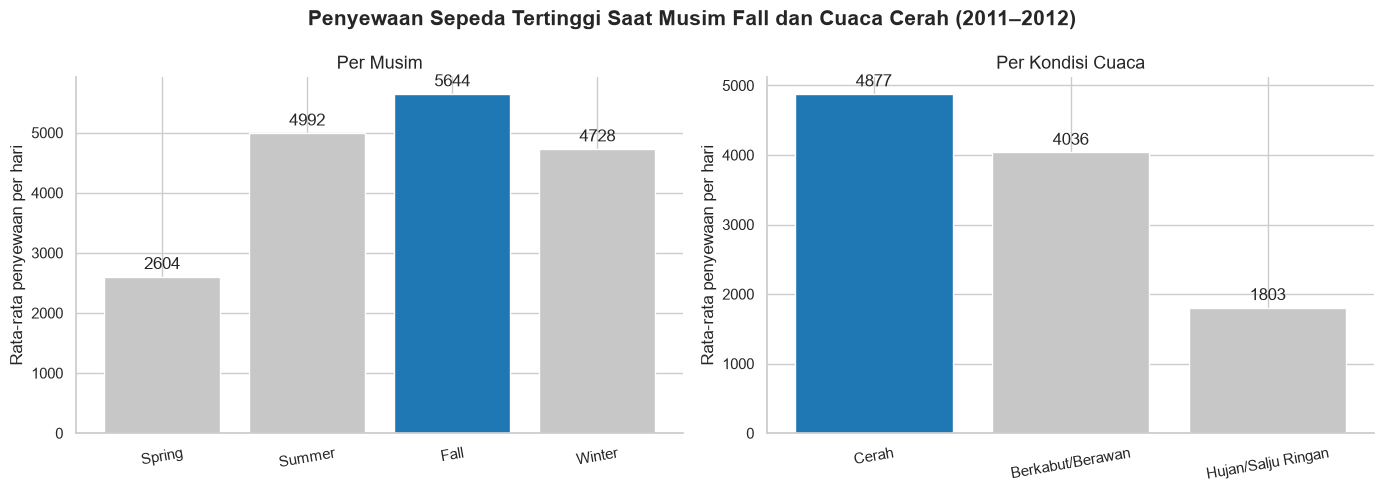

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, stats, title in zip(
    axes, [season_stats, weather_stats],
    ["Per Musim", "Per Kondisi Cuaca"]
):
    vals = stats["mean"]
    colors = ["#1f77b4" if v == vals.max() else "#c7c7c7" for v in vals]
    bars = ax.bar(stats.index, vals, color=colors)
    ax.bar_label(bars, fmt="%.0f", padding=3)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("Rata-rata penyewaan per hari")
    ax.tick_params(axis="x", labelrotation=10)
    sns.despine(ax=ax)
fig.suptitle("Penyewaan Sepeda Tertinggi Saat Musim Fall dan Cuaca Cerah (2011–2012)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Pertanyaan 2:

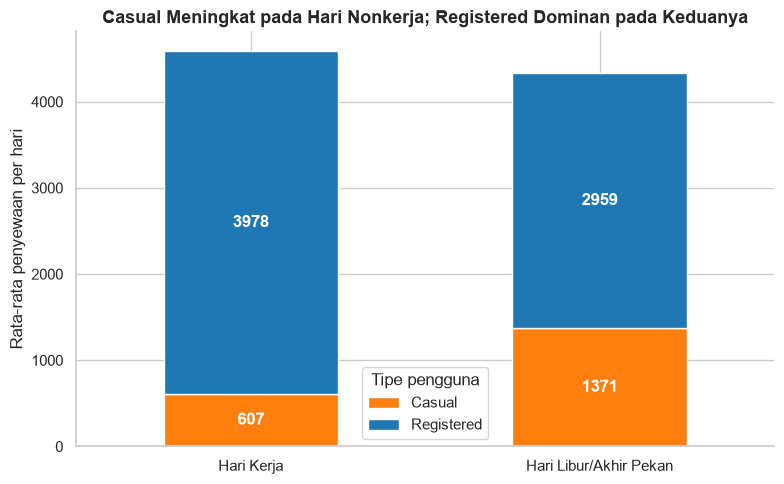

In [75]:
avg = usertype[["casual_users", "registered_users"]].copy()
avg.columns = ["Casual", "Registered"]

ax = avg.plot(kind="bar", stacked=True, color=["#ff7f0e", "#1f77b4"],
              figsize=(8, 5), rot=0)
for container in ax.containers:
    if isinstance(container, BarContainer):
        ax.bar_label(container, fmt="%.0f", label_type="center",
                     color="white", fontweight="bold")
ax.set_title("Casual Meningkat pada Hari Nonkerja; Registered Dominan pada Keduanya",
             fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.legend(title="Tipe pengguna")
sns.despine()
plt.tight_layout()
plt.show()


### Pertanyaan 3:

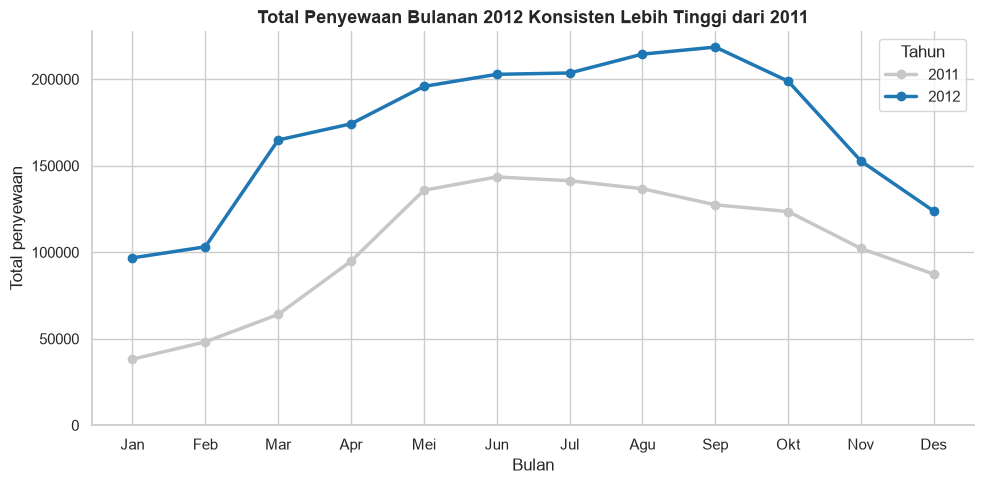

In [76]:
bulan = ["Jan","Feb","Mar","Apr","Mei","Jun","Jul","Agu","Sep","Okt","Nov","Des"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly.index, monthly[2011], marker="o", color="#c7c7c7", linewidth=2.5, label="2011")
ax.plot(monthly.index, monthly[2012], marker="o", color="#1f77b4", linewidth=2.5, label="2012")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(bulan)
ax.set_ylim(bottom=0)
ax.set_title("Total Penyewaan Bulanan 2012 Konsisten Lebih Tinggi dari 2011",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Bulan")
ax.set_ylabel("Total penyewaan")
ax.legend(title="Tahun")
sns.despine()
plt.tight_layout()
plt.show()

**Insight Visualisasi:**
- Grafik menegaskan Fall memiliki rata-rata penyewaan tertinggi dan Spring terendah; cuaca cerah tertinggi, sementara hujan/salju ringan terendah.
- Pada kedua tipe hari, registered menyumbang rata-rata harian lebih besar. Namun, jumlah casual meningkat jelas pada hari nonkerja, sehingga promosi rekreasi lebih relevan diarahkan ke akhir pekan dan hari libur.
- Total bulanan pada 2012 lebih tinggi daripada bulan yang sama pada 2011; grafik menunjukkan pola musiman dan kenaikan terbesar secara tahunan tidak selalu berarti setiap bulan tumbuh dengan laju yang sama.


## Analisis Lanjutan (Opsional)

**Tujuan:** Mengelompokkan hari berdasarkan suhu dan tingkat permintaan menggunakan aturan sederhana, lalu membandingkan proporsi kategori permintaan pada tiap rentang suhu. Analisis ini bersifat deskriptif dan tidak menggunakan algoritma machine learning.
- Kategori suhu: Dingin (<10 C), Sejuk (10 to <20 C), Hangat (20 to <30 C), Panas (>=30 C).
- Kategori permintaan: Rendah (<3.000), Sedang (3.000 to <6.000), Tinggi (>=6.000 sewa/hari).


In [77]:
day_df["temp_category"] = pd.cut(
    day_df["temp_c"], bins=[-np.inf, 10, 20, 30, np.inf], right=False,
    labels=["Dingin (<10 C)", "Sejuk (10 to <20 C)",
            "Hangat (20 to <30 C)", "Panas (>=30 C)"])

day_df["demand_category"] = pd.cut(
    day_df["total_rentals"], bins=[0, 3000, 6000, np.inf],
    labels=["Rendah", "Sedang", "Tinggi"], right=False)

display(day_df.groupby("temp_category", observed=True)["total_rentals"]
        .agg(["count", "mean"]).round(0))

demand_by_temp = pd.crosstab(day_df["temp_category"], day_df["demand_category"],
                             normalize="index") * 100
demand_by_temp.round(1)


,count,mean
temp_category,,
Dingin (<10 C),60,1678.0
Sejuk (10 to <20 C),299,3692.0
Hangat (20 to <30 C),300,5662.0
Panas (>=30 C),72,5410.0


demand_category,Rendah,Sedang,Tinggi
temp_category,,,
Dingin (<10 C),91.7,8.3,0.0
Sejuk (10 to <20 C),35.5,56.5,8.0
Hangat (20 to <30 C),3.7,53.3,43.0
Panas (>=30 C),0.0,62.5,37.5


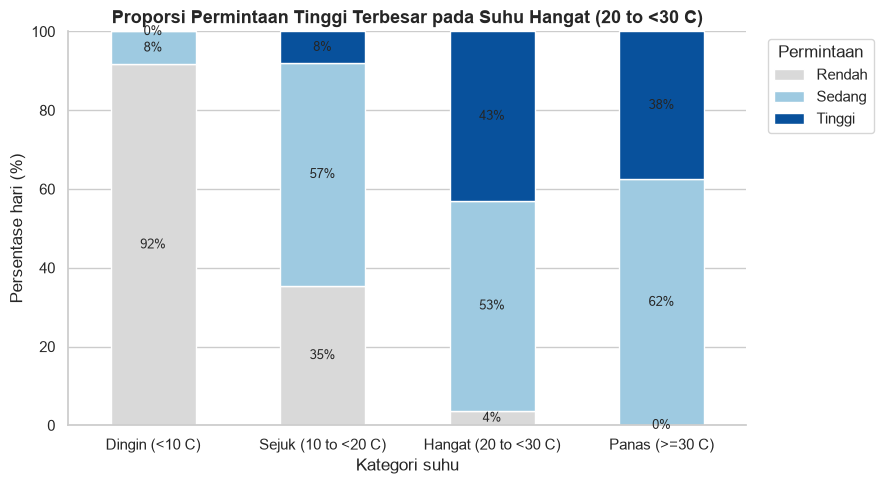

In [78]:
ax = demand_by_temp.plot(kind="bar", stacked=True, figsize=(9, 5), rot=0,
                         color=["#d9d9d9", "#9ecae1", "#08519c"])
for container in ax.containers:
    if isinstance(container, BarContainer):
        ax.bar_label(container, fmt="%.0f%%", label_type="center", fontsize=9)
ax.set_title("Proporsi Permintaan Tinggi Terbesar pada Suhu Hangat (20 to <30 C)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Kategori suhu")
ax.set_ylabel("Persentase hari (%)")
ax.legend(title="Permintaan", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()


**Insight:**
- Proporsi hari dengan permintaan tinggi terbesar terjadi pada suhu Hangat (20 to <30 C), yaitu 43,0%; pada suhu Panas proporsinya 37,5%. Jadi, pola ini tidak terus meningkat pada suhu tertinggi.
- Pada suhu Dingin (<10 C), 91,7% hari berada dalam kategori permintaan rendah dan tidak ada hari berkategori tinggi. Temuan ini menunjukkan hubungan deskriptif, bukan bukti bahwa suhu menjadi satu-satunya penyebab perubahan permintaan.


In [79]:
day_df.to_csv("dashboard/main_data.csv", index=False)

## Conclusion & Recommendation

**Kesimpulan**

- **Pertanyaan 1:** Musim Fall menghasilkan rata-rata penyewaan tertinggi (5.644 per hari), sedangkan Spring terendah (2.604); selisihnya 116,7%. Cuaca Cerah tertinggi (4.877 per hari) dan Hujan/Salju Ringan terendah (1.803); selisihnya 170,4%.
- **Pertanyaan 2:** Rata-rata casual meningkat dari 607 pada hari kerja menjadi 1.371 pada hari nonkerja; kontribusinya naik dari 13,2% menjadi 31,7%. Rata-rata registered justru lebih tinggi pada hari kerja (3.978 vs 2.959) dan kontribusinya 86,8% pada hari kerja serta 68,3% pada hari nonkerja.
- **Pertanyaan 3:** Total penyewaan meningkat 64,9% pada 2012 dibanding 2011. Pertumbuhan YoY tertinggi terjadi pada Maret (157,4%) dan terendah pada Juni (41,3%).
- **Analisis lanjutan:** Proporsi permintaan tinggi terbesar ada pada suhu Hangat (20 to <30 C), sebesar 43,0%; 91,7% hari Dingin memiliki permintaan rendah.


### Rekomendasi (Action Item)

1. Siapkan armada lebih banyak menjelang musim Fall dan periode bercuaca cerah; manfaatkan musim Spring yang berpermintaan lebih rendah untuk perawatan terjadwal.
2. Arahkan promosi penyewaan rekreasi dan paket harian kepada pengguna casual pada akhir pekan/hari libur. Uji program langganan atau loyalitas untuk mendorong penggunaan berulang tanpa mengasumsikan seluruh casual akan beralih menjadi registered.
3. Pantau prakiraan cuaca dan siapkan strategi operasional yang aman saat hujan, misalnya komunikasi kondisi layanan dan penyesuaian ketersediaan armada; rata-rata penyewaan pada hujan/salju ringan 63,0% lebih rendah daripada cuaca cerah.
4. Gunakan pertumbuhan per bulan untuk menyusun kapasitas, khususnya evaluasi lonjakan Maret dan kebutuhan puncak penyewaan pada bulan-bulan dengan volume tinggi. Validasi pola ini dengan data tahun terbaru sebelum menetapkan target operasional.
